In [ ]:
!pip install pandas numpy matplotlib scikit-learn

In [ ]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv"
df = pd.read_csv(url)
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
print("Missing Values: ", df.isnull().sum())
print("Duplicate Values: ", df.duplicated().sum())

Missing Values:  Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64
Duplicate Values:  0


In [ ]:
df = df.drop(columns=["Unnamed: 0"])
df = df.dropna()
df = df.drop_duplicates()
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=["Sales"])
y = df["Sales"]

x_pool, x_test, y_pool, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sizes, rmses, r2s = [], [], []
for size in [0.5, 0.7, 0.8]:
    n = int(len(df) * size)          # fraction of the FULL dataset
    model = LinearRegression()
    model.fit(x_pool.iloc[:n], y_pool.iloc[:n])
    pred = model.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    sizes.append(n); rmses.append(rmse); r2s.append(r2)
    print(f"{int(size*100)}% ({n} rows) -> RMSE: {rmse:.4f}, R2: {r2:.4f}")

50% (100 rows) -> RMSE: 1.7487, R2: 0.9031
70% (140 rows) -> RMSE: 1.7926, R2: 0.8982
80% (160 rows) -> RMSE: 1.7816, R2: 0.8994


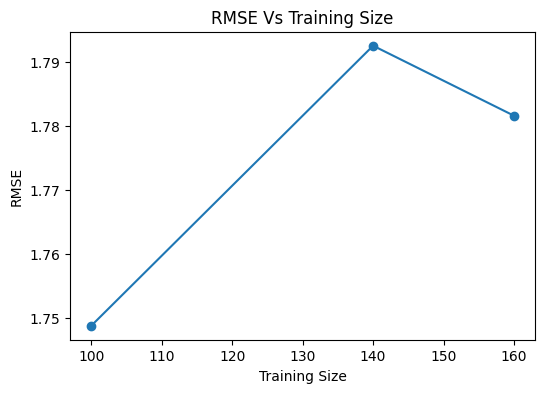

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(sizes,rmses , marker="o")
plt.title("RMSE Vs Training Size")
plt.xlabel("Training Size")
plt.ylabel("RMSE")
plt.show()